# Partie 1 : Exploration et préparation des données

**Cours :** 030513 IFM, Intelligence artificielle appliquée au prétraitement des données (automne 2026)

**Évaluation sommative 2 :** Création des pipelines (Prof. Nadjate Saïdani)

**Équipe :**
- Akiella Wankoua, Blonde Béatrice
- Essomba, Martin Junior
- Gouater, Rene Eutyche
- Misse, Anthony

**But du notebook :** comprendre le jeu de données, repérer les problèmes de qualité, choisir la cible et les variables explicatives, puis séparer les données en entraînement (80 %) et test (20 %).

**Ce que le notebook utilise :**
- `donnees/brutes/hotels.csv` (jeu de données Hotel Booking Demand)

**Ce que le notebook produit pour la suite :**
- `donnees/preparees/X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv` (lus par le notebook 02)
- `figures/01_repartition_cible.png` (pour les diapositives)

## Mise en situation

Une entreprise hôtelière veut un modèle qui prédit si une réservation risque d'être annulée.
- Les données viennent de deux hôtels au Portugal : un hôtel en ville (City Hotel) et un hôtel de vacances (Resort Hotel).
- La variable cible est `is_canceled` : 1 = réservation annulée, 0 = réservation non annulée.

## Importation des librairies

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split

# Chemins du projet (ce notebook est dans le dossier notebooks/)
DOSSIER_DONNEES = Path("../donnees")
DOSSIER_PREPAREES = DOSSIER_DONNEES / "preparees"
DOSSIER_FIGURES = Path("../figures")
DOSSIER_PREPAREES.mkdir(parents=True, exist_ok=True)
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

# Versions utilisées (utile pour obtenir les mêmes résultats sur un autre ordinateur)
print("pandas :", pd.__version__)
print("scikit-learn :", sklearn.__version__)

pandas : 1.5.3
scikit-learn : 1.9.1


**Ce qu'on observe :**

- Nous utilisons pandas 1.5.3 et scikit-learn 1.9.1.
- Avec d'autres versions, certains chiffres peuvent changer un peu.

## 1. Importer le jeu de données et examiner sa structure

In [2]:
df = pd.read_csv(DOSSIER_DONNEES / "brutes" / "hotels.csv")

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
df.head()

Nombre de lignes : 119390
Nombre de colonnes : 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


**Ce qu'on observe :**

- Le jeu de données a 119 390 lignes et 32 colonnes.
- Chaque ligne est une réservation.
- On voit déjà des valeurs manquantes (NaN) dans `agent` et `company`.
- La colonne `reservation_status` (par exemple « Check-Out ») décrit ce qui s'est passé après la réservation. On en reparle dans la partie sur la fuite de données.

In [3]:
# Type de chaque colonne et nombre de valeurs non vides
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

**Ce qu'on observe :**

- 16 colonnes sont des entiers (int64), 4 sont des nombres décimaux (float64) et 12 sont du texte (object).
- Certaines colonnes ont moins de 119 390 valeurs non vides, donc des valeurs manquantes :
    - `children` : 119 386 ;
    - `country` : 118 902 ;
    - `agent` : 103 050 ;
    - `company` : 6 797 seulement.
- `children` est en float64 à cause de ses valeurs manquantes, alors que c'est un nombre d'enfants.

In [4]:
# Statistiques des colonnes numériques
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


**Ce qu'on observe :**

- La moyenne de `is_canceled` est 0,37. Comme la cible vaut 0 ou 1, cette moyenne est la part des réservations annulées dans les données brutes.
- Plusieurs maximums sont très loin du 75e centile (colonne 75%) :
    - `lead_time` : 160 au 75e centile, 737 au maximum ;
    - `adr` : 126 au 75e centile, 5 400 au maximum ;
    - `adults` : 2 au 75e centile, 55 au maximum.
- `adr` a un minimum de -6,38 : un prix négatif n'est pas normal.
- Pour `days_in_waiting_list`, la valeur est 0 jusqu'au 75e centile : la plupart des réservations n'ont pas d'attente.
- `arrival_date_year` va de 2015 à 2017.

## 2. Variables numériques, variables catégorielles et qualité des données

In [5]:
colonnes_numeriques = df.select_dtypes(include="number").columns.tolist()
colonnes_categorielles = df.select_dtypes(exclude="number").columns.tolist()

print("Variables numériques :", len(colonnes_numeriques))
print(colonnes_numeriques)
print()
print("Variables catégorielles :", len(colonnes_categorielles))
print(colonnes_categorielles)

Variables numériques : 20
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Variables catégorielles : 12
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


**Ce qu'on observe :**

- Selon le type pandas, il y a 20 variables numériques et 12 variables catégorielles.
- Ce classement automatique n'est pas parfait (voir la cellule suivante).
- `reservation_status_date` est une date enregistrée comme du texte.

In [6]:
# Certaines colonnes « numériques » sont en fait des codes ou des catégories
print("Valeurs différentes dans agent :", df["agent"].nunique())
print("Valeurs différentes dans company :", df["company"].nunique())
print("Valeurs dans is_repeated_guest :", sorted(df["is_repeated_guest"].unique().tolist()))
print("Valeurs dans arrival_date_year :", sorted(df["arrival_date_year"].unique().tolist()))

Valeurs différentes dans agent : 333
Valeurs différentes dans company : 352
Valeurs dans is_repeated_guest : [0, 1]
Valeurs dans arrival_date_year : [2015, 2016, 2017]


**Ce qu'on observe :**

- `agent` a 333 valeurs différentes et `company` en a 352.
    - Ce sont des numéros d'identification, pas des quantités : l'agent 240 n'est pas « plus grand » que l'agent 9.
    - Il faut donc traiter `agent` comme une catégorie.
- `is_repeated_guest` vaut seulement 0 ou 1 : c'est une variable binaire.
- `arrival_date_year` a seulement 3 valeurs (2015, 2016 et 2017).
- `is_canceled` est numérique, mais c'est notre cible.

### Valeurs manquantes

In [7]:
manquants = df.isna().sum()
manquants = manquants[manquants > 0].sort_values(ascending=False)

pd.DataFrame({
    "nb_manquants": manquants,
    "pourcentage": (manquants / len(df) * 100).round(2),
})

,nb_manquants,pourcentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


**Ce qu'on observe :**

- `company` est vide dans 94,31 % des lignes. Elle donne trop peu d'information : on la supprime.
- `agent` est vide dans 13,69 % des lignes. Une case vide veut dire que la réservation n'est pas passée par un agent : on remplace par « 0 ».
- `country` est vide dans 0,41 % des lignes : le pipeline du notebook 02 remplacera ces cases par « Inconnu ».
- `children` a seulement 4 valeurs manquantes : on met 0.

### Doublons

In [8]:
nb_doublons = df.duplicated().sum()
print("Lignes en double :", nb_doublons)
print("Part des lignes en double :", round(nb_doublons / len(df) * 100, 1), "%")

# Test : si on garde les doublons, une même ligne peut se retrouver dans le train ET dans le test
train_essai, test_essai = train_test_split(df, test_size=0.20, random_state=42)
copies = test_essai.merge(train_essai.drop_duplicates(), how="inner")
print("Lignes du test qui ont une copie exacte dans le train :", len(copies), "sur", len(test_essai))

Lignes en double : 31994
Part des lignes en double : 26.8 %


Lignes du test qui ont une copie exacte dans le train : 7727 sur 23878


**Ce qu'on observe :**

- 31 994 lignes sont des copies exactes d'une autre ligne, soit 26,8 % des données.
- Le jeu de données n'a pas de numéro de réservation. On ne peut donc pas savoir si ce sont de vraies réservations différentes (par exemple un groupe) ou des lignes copiées.
- Notre test montre le risque : si on garde les doublons, 7 727 lignes du test sur 23 878 ont une copie exacte dans le train.
    - Le modèle aurait déjà « vu » ces réservations pendant l'entraînement.
    - Son score sur le test serait trop optimiste.
- **Décision :** on supprime les doublons.

### Valeurs aberrantes ou incohérentes

In [9]:
print("Prix moyen par nuit (adr) négatif :", (df["adr"] < 0).sum())
print("Prix moyen par nuit (adr) maximum :", df["adr"].max())
print("Nombre d'adultes maximum :", df["adults"].max())
print("Nombre de bébés maximum :", df["babies"].max())

total_clients = df["adults"] + df["children"].fillna(0) + df["babies"]
print("Réservations sans aucun client :", (total_clients == 0).sum())

total_nuits = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print("Réservations de 0 nuit :", (total_nuits == 0).sum())

Prix moyen par nuit (adr) négatif : 1
Prix moyen par nuit (adr) maximum : 5400.0
Nombre d'adultes maximum : 55
Nombre de bébés maximum : 10
Réservations sans aucun client : 180
Réservations de 0 nuit : 715


**Ce qu'on observe :**

- 1 réservation a un prix négatif : c'est une erreur, on la retire.
- Un prix de 5 400 par nuit, 55 adultes ou 10 bébés sont des valeurs extrêmes. On les garde ici, mais notre transformateur personnalisé va les limiter (notebook 03).
- 180 réservations n'ont aucun client (0 adulte, 0 enfant, 0 bébé). Ce n'est pas possible : on les retire.
- 715 réservations ont 0 nuit. Ce sont peut-être des réservations de jour : on les garde.

### Fuite de données (data leakage)

Une fuite de données arrive quand une variable donne une information connue **seulement après** le résultat.
Le modèle aurait alors un excellent score en test, mais il serait inutile dans la vraie vie : au moment de la réservation, on ne connaît pas encore cette information.

In [10]:
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


**Ce qu'on observe :**

- `reservation_status` donne exactement la cible :
    - « Canceled » et « No-Show » ont toujours `is_canceled` = 1 ;
    - « Check-Out » a toujours `is_canceled` = 0.
- Cette information arrive après le résultat. On retire donc `reservation_status`, et aussi `reservation_status_date` (la date de ce dernier statut).

In [11]:
# La chambre attribuée est-elle connue au moment de la réservation ?
chambre_differente = df["reserved_room_type"] != df["assigned_room_type"]
taux_si_differente = round(df.loc[chambre_differente, "is_canceled"].mean() * 100, 1)
taux_si_meme = round(df.loc[~chambre_differente, "is_canceled"].mean() * 100, 1)

print("Réservations avec une chambre attribuée différente :", chambre_differente.sum())
print("Taux d'annulation si chambre différente :", taux_si_differente, "%")
print("Taux d'annulation si même chambre :", taux_si_meme, "%")

Réservations avec une chambre attribuée différente : 14917
Taux d'annulation si chambre différente : 5.4 %
Taux d'annulation si même chambre : 41.6 %


**Ce qu'on observe :**

- 14 917 réservations ont une chambre attribuée différente de la chambre réservée.
- Le taux d'annulation est de 5,4 % quand la chambre est différente, contre 41,6 % quand c'est la même chambre.
- Explication possible : la chambre est souvent attribuée à l'arrivée du client. Un client qui annule n'arrive jamais, donc sa chambre change rarement.
- `assigned_room_type` donne donc une information de l'avenir : on la retire. On garde `reserved_room_type`, qui est connue au moment de la réservation.

### Nettoyage

Décisions prises à partir des constats ci-dessus :
- Supprimer les doublons exacts.
- Retirer la ligne avec un prix négatif.
- Retirer les réservations sans aucun client.
- Remplir les valeurs manquantes dont le sens est clair :
    - `children` vide : on met 0 enfant ;
    - `agent` vide : on met « 0 » (pas d'agent), et on garde `agent` comme du texte car c'est un code.
- Supprimer `company` : la colonne est presque vide.
- Laisser les valeurs manquantes de `country` : le pipeline du notebook 02 va les remplacer par « Inconnu ».

Ces remplissages utilisent une valeur fixe (0 ou « 0 »). Ils ne dépendent pas des autres lignes, donc on peut les faire avant la séparation train / test sans fuite d'information.

In [12]:
lignes_depart = len(df)

# 1) Supprimer les doublons exacts
df = df.drop_duplicates()
print("Après suppression des doublons :", len(df), "lignes")

# 2) Retirer le prix négatif (erreur de saisie)
df = df[df["adr"] >= 0]
print("Après retrait du prix négatif :", len(df), "lignes")

# 3) Retirer les réservations sans aucun client
total_clients = df["adults"] + df["children"].fillna(0) + df["babies"]
df = df[total_clients > 0]
print("Après retrait des réservations vides :", len(df), "lignes")

# 4) Remplir les valeurs manquantes dont le sens est clair
# children vide : pas d'information, donc 0 enfant
df["children"] = df["children"].fillna(0)
# agent vide : pas d'agent, donc "0" (agent est un code, on le garde en texte)
df["agent"] = df["agent"].fillna(0).astype(int).astype(str)

# 5) Supprimer company (presque vide)
df = df.drop(columns=["company"])

print()
print("Lignes retirées au total :", lignes_depart - len(df))
print("Dimensions finales :", df.shape)
print("Valeurs manquantes restantes :")
print(df.isna().sum()[df.isna().sum() > 0])

Après suppression des doublons : 87396 lignes
Après retrait du prix négatif : 87395 lignes
Après retrait des réservations vides : 87229 lignes



Lignes retirées au total : 32161
Dimensions finales : (87229, 31)
Valeurs manquantes restantes :


country    447
dtype: int64


**Ce qu'on observe :**

- La suppression des doublons fait passer le jeu de 119 390 à 87 396 lignes.
- Le retrait du prix négatif donne 87 395 lignes, puis le retrait des réservations vides donne 87 229 lignes.
- Au total, 32 161 lignes sont retirées. Il reste 87 229 lignes et 31 colonnes.
- Il reste 447 valeurs manquantes, toutes dans `country`. C'est voulu : le pipeline du notebook 02 s'en occupe.

## 3. Variables explicatives et variable cible

In [13]:
# Variable cible : 1 = réservation annulée, 0 = non annulée
cible = "is_canceled"

# Colonnes retirées des variables explicatives : la cible + les colonnes avec fuite de données
colonnes_fuite = ["reservation_status", "reservation_status_date", "assigned_room_type"]

X = df.drop(columns=[cible] + colonnes_fuite)
y = df[cible]

print("Nombre de variables explicatives :", X.shape[1])
print(X.columns.tolist())

Nombre de variables explicatives : 27
['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


**Ce qu'on observe :**

- Il reste 27 variables explicatives.
- Nous avons retiré :
    - la cible `is_canceled` ;
    - les 3 colonnes avec fuite de données.

                 nombre  pourcentage
0 = non annulée   63220         72.5
1 = annulée       24009         27.5


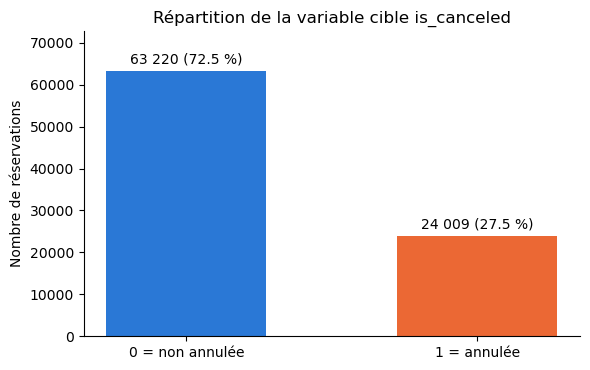

In [14]:
repartition = pd.DataFrame({
    "nombre": y.value_counts().sort_index(),
    "pourcentage": (y.value_counts(normalize=True).sort_index() * 100).round(1),
})
repartition.index = ["0 = non annulée", "1 = annulée"]
print(repartition)

# Graphique pour les diapositives
fig, ax = plt.subplots(figsize=(6, 3.8))
barres = ax.bar(repartition.index, repartition["nombre"], color=["#2a78d6", "#eb6834"], width=0.55)
etiquettes = [f"{n:,} ({p} %)".replace(",", " ") for n, p in zip(repartition["nombre"], repartition["pourcentage"])]
ax.bar_label(barres, labels=etiquettes, padding=3)
ax.set_title("Répartition de la variable cible is_canceled")
ax.set_ylabel("Nombre de réservations")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, repartition["nombre"].max() * 1.15)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "01_repartition_cible.png", dpi=120)
plt.show()

**Ce qu'on observe :**

- 63 220 réservations ne sont pas annulées (72,5 %).
- 24 009 réservations sont annulées (27,5 %).
- Les classes ne sont pas équilibrées : un peu plus d'une réservation sur quatre est annulée.
- Dans les données brutes, la moyenne de `is_canceled` était 0,37. Les doublons supprimés contenaient donc beaucoup d'annulations.
- Conséquences pour la suite :
    - on garde la même proportion dans le train et le test (`stratify=y`) ;
    - au notebook 05, on aide le modèle à mieux repérer les annulations (`class_weight="balanced"`).

## 4. Séparation entraînement (80 %) et test (20 %)

In [15]:
# test_size=0.20 : 20 % des lignes pour le test
# random_state=42 : mêmes résultats à chaque exécution
# stratify=y : même proportion d'annulations dans les deux ensembles
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Taux d'annulation dans le train :", round(y_train.mean() * 100, 1), "%")
print("Taux d'annulation dans le test :", round(y_test.mean() * 100, 1), "%")

X_train : (69783, 27) | X_test : (17446, 27)
Taux d'annulation dans le train : 27.5 %
Taux d'annulation dans le test : 27.5 %


**Ce qu'on observe :**

- Le train a 69 783 lignes et le test 17 446 lignes. Les deux ont 27 colonnes.
- Le taux d'annulation est de 27,5 % dans les deux ensembles, grâce à `stratify=y`.
- `random_state=42` donne toujours la même séparation. Toute l'équipe obtient donc les mêmes résultats.

## Sauvegarde pour le notebook 02

In [16]:
X_train.to_csv(DOSSIER_PREPAREES / "X_train.csv", index=False)
X_test.to_csv(DOSSIER_PREPAREES / "X_test.csv", index=False)
y_train.to_csv(DOSSIER_PREPAREES / "y_train.csv", index=False)
y_test.to_csv(DOSSIER_PREPAREES / "y_test.csv", index=False)

print("Fichiers créés dans donnees/preparees/ :")
for fichier in sorted(DOSSIER_PREPAREES.glob("*.csv")):
    print("-", fichier.name)

Fichiers créés dans donnees/preparees/ :
- X_test.csv
- X_train.csv
- y_test.csv
- y_train.csv


**Ce qu'on observe :**

- Les 4 fichiers sont créés dans `donnees/preparees/`.
- Le notebook 02 commence en lisant ces fichiers. Il n'a pas besoin de refaire le nettoyage.